## Multinomial Logistic Regression and KNN

We are going to do some analysis for the wine dataset. https://archive.ics.uci.edu/dataset/109/wine

These data are the results of a chemical analysis of wines grown in the same region of Italy, but derived from different cultivars. (A cultivaer is a cultivated plant that people have bred/selected for different traits. It is a portmanteau of "cultivated variety". See wikipedia for more details: https://en.wikipedia.org/wiki/Cultivar)

Our goal is to predict the **cultivar** (3 classes) of 178 wines from 13 chemical measurements. We will do this first using multinomial logistic regression and then KNN. 

Game plan:
1. Hold out a 20% test set.
2. On the training set, use stratified 5-fold CV and different `C` and `l1_ratio` values to find the best model for multinomial logistic regression.
3. Use the same folds to choose `k` for **KNN**.
4. Compare the two models, then evaluate each **once** on the test set.

Note: The precise results reported in this notebook are sensitive to the random seed chosen. Changing the seed could change (for example) the best model chosen, the size of the gap between models, or which wines are mispredicted. The main conclusions should not change: both models far outperform the baseline, and logistic regression does at least as well as KNN in cross-validation. 

*AI disclosure: The code in this notebook was generated with the assistance of Claude. I gave Claude a pretty detailed prompt, then I went through and modified both the code itself and the explanations provided. I made sure I could execute and validate the output for code written.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import log_loss, ConfusionMatrixDisplay

### Load the data

Note: Normally, we upload the data from a .csv file in our data sub directory. In this instance, we are using the wine dataset, which is included as a dataset in sklearn. Some of the other datasets we have used in the past are also available in sklearn, but I've chosen to include them as .csv files to practice ingesting data. 

In [2]:
# Let's load and explore the data. 
# Note that the data takes a slightly different form than a standard .csv, but is well documented in sklearn

wine = load_wine(as_frame=True)
X = wine.data
y = wine.target   # 0, 1, 2 = the three cultivars

print(X.shape)
y.value_counts().sort_index()

(178, 13)


target
0    59
1    71
2    48
Name: count, dtype: int64

In [3]:
X.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [4]:
# Let's look at the ranges, mean, and standard deviation of each of these numeric variables
X.describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


All 13 predictors are numeric, but on very different scales (e.g. `proline` is in the hundreds, `hue` is around 1). Both lasso and KNN depend on scale, so we standardize everything.

### Train/test split

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=113
)
print(f"Training set: {X_train.shape}")
print(f"Test set:     {X_test.shape}")

Training set: (142, 13)
Test set:     (36, 13)


### CV folds and a baseline

In [6]:
# Same folds for every model so comparisons are fair
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=224)

# Baseline: predict the training class proportions for every wine
class_props = y_train.value_counts(normalize=True).sort_index().values

#np.tile (class_props, (len(y_train), 1)) gives the baseline probability for every class
ll_base = log_loss(y_train, np.tile(class_props, (len(y_train), 1)))
print(f"Base-rate log loss: {ll_base:.4f}")

Base-rate log loss: 1.0851


In [7]:
# Calculating log_loss by hand
y_ll = pd.get_dummies(y_train).sort_index(axis=1).values 
p_ll = np.tile(class_props, (len(y_train), 1)) 
ll_by_hand = -np.mean(np.sum(y_ll * np.log(p_ll), axis=1))
ll_by_hand

np.float64(1.0851289335410863)

In [8]:
# We can look at each of the elements above individually to see what is going on. 
# Equation for log loss for multinomial regression is on slide 56 of Classification_and_GLMs.pptx

#np.tile(class_props, (len(y_train), 1))
#p_ll
#y_ll
y_ll * np.log(p_ll)
#np.sum(y_ll * np.log(p_ll), axis=1)


array([[-1.10567946, -0.        , -0.        ],
       [-0.        , -0.91277579, -0.        ],
       [-0.        , -0.        , -1.3182409 ],
       [-0.        , -0.        , -1.3182409 ],
       [-1.10567946, -0.        , -0.        ],
       [-1.10567946, -0.        , -0.        ],
       [-0.        , -0.        , -1.3182409 ],
       [-0.        , -0.91277579, -0.        ],
       [-1.10567946, -0.        , -0.        ],
       [-1.10567946, -0.        , -0.        ],
       [-1.10567946, -0.        , -0.        ],
       [-0.        , -0.91277579, -0.        ],
       [-0.        , -0.91277579, -0.        ],
       [-1.10567946, -0.        , -0.        ],
       [-0.        , -0.        , -1.3182409 ],
       [-0.        , -0.        , -1.3182409 ],
       [-0.        , -0.91277579, -0.        ],
       [-1.10567946, -0.        , -0.        ],
       [-0.        , -0.91277579, -0.        ],
       [-0.        , -0.91277579, -0.        ],
       [-0.        , -0.91277579, -0.   

**Helper functions**
* Similar to what we used last week 
* `cv_scores`: log_loss: mean and SD across the 5 folds.
* `cv_pred`: out-of-fold predicted class for every training wine (for a pooled confusion matrix).

In [9]:
def cv_scores(model):
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=["neg_log_loss"])
    return {
        "log loss (mean)": -res["test_neg_log_loss"].mean(),
        "log loss (sd)": res["test_neg_log_loss"].std(),
    }

def cv_pred(model):
    return cross_val_predict(model, X_train, y_train, cv=cv)

## Multinomial logistic regression

With 3 classes, `LogisticRegression` fits a **multinomial** model: one set of 13 coefficients per class (39 total coefficients), and a softmax turns the three linear scores into probabilities that sum to 1.

In [10]:
def make_model(C, l1_ratio):
    return Pipeline(steps=[
        ("scale", StandardScaler()),
        ("model", LogisticRegression(C=C, l1_ratio=l1_ratio, solver="saga", max_iter=50000, random_state=48)),
    ])

C_values = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000]
l1_ratios = {"lasso": 1, "enet 0.75": 0.75, "enet 0.5": 0.5, "enet 0.25": 0.25, "ridge": 0}

all_results = pd.DataFrame([{"model": name, "C": C, **cv_scores(make_model(C, r))}
                            for name, r in l1_ratios.items() for C in C_values])
all_results.round(4)

,model,C,log loss (mean),log loss (sd)
0,lasso,0.01,1.0859,0.0073
1,lasso,0.03,0.8422,0.0233
2,lasso,0.10,0.3057,0.0579
3,lasso,0.30,0.1571,0.0479
4,lasso,1.00,0.0988,0.0469
5,lasso,3.00,0.0902,0.0669
6,lasso,10.00,0.1014,0.0936
7,lasso,30.00,0.0995,0.0959
8,lasso,100.00,0.0964,0.0934
9,lasso,300.00,0.1005,0.0860


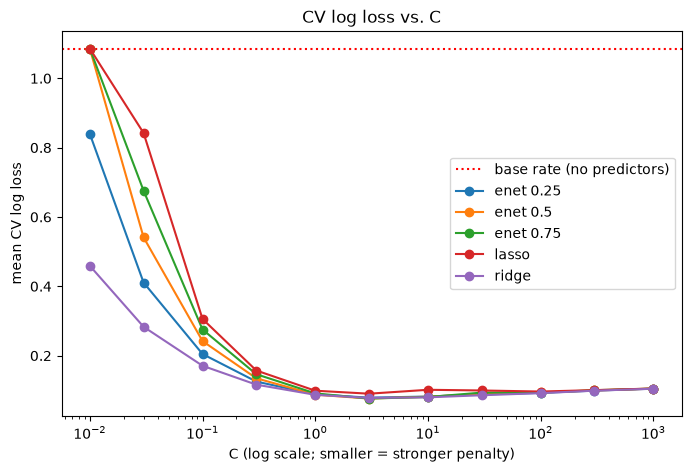

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, g in all_results.groupby("model"):
    ax.errorbar(g["C"], g["log loss (mean)"], marker="o", capsize=3, label=name)
ax.axhline(ll_base, color="red", ls=":", label="base rate (no predictors)")
ax.set(xscale="log", xlabel="C (log scale; smaller = stronger penalty)",
       ylabel="mean CV log loss", title="CV log loss vs. C")
ax.legend()
plt.show()

In [12]:
# From all of the values of C that we tried above, let's select the best one
# We will identify the simplest model that is within one standard error of the lowest
best = all_results.loc[all_results["log loss (mean)"].idxmin()]
cutoff = best["log loss (mean)"] + best["log loss (sd)"] / np.sqrt(5)   

candidates = all_results[all_results["log loss (mean)"] <= cutoff].copy()
candidates["l1_ratio"] = candidates["model"].map(l1_ratios)

# Fit each candidate on the full training set and count its nonzero coefficients
candidates["nonzero coefs (of 39)"] = [
    int((make_model(C, r).fit(X_train, y_train).named_steps["model"].coef_ != 0).sum())
    for C, r in zip(candidates["C"], candidates["l1_ratio"])
]
simplest = candidates.sort_values(["nonzero coefs (of 39)", "C"]).iloc[0]   # fewest nonzero, then smallest C

C_best, method_best, l1_best = simplest["C"], simplest["model"], simplest["l1_ratio"]
print(f"Simplest within 1 SE: {method_best} (l1_ratio = {l1_best}), C = {C_best}")
model_best = make_model(C_best, l1_best)
candidates.round(4)

Simplest within 1 SE: lasso (l1_ratio = 1.0), C = 3.0


,model,C,log loss (mean),log loss (sd),l1_ratio,nonzero coefs (of 39)
5,lasso,3.0,0.0902,0.0669,1.00,15
15,enet 0.75,1.0,0.0911,0.0397,0.75,16
16,enet 0.75,3.0,0.0762,0.0474,0.75,18
17,enet 0.75,10.0,0.0806,0.0651,0.75,22
18,enet 0.75,30.0,0.0933,0.0871,0.75,26
19,enet 0.75,100.0,0.0933,0.0786,0.75,33
26,enet 0.5,1.0,0.0874,0.0359,0.50,22
27,enet 0.5,3.0,0.0762,0.0445,0.50,24
28,enet 0.5,10.0,0.0816,0.0600,0.50,30
29,enet 0.5,30.0,0.0893,0.0705,0.50,32


### Coefficients of the chosen model

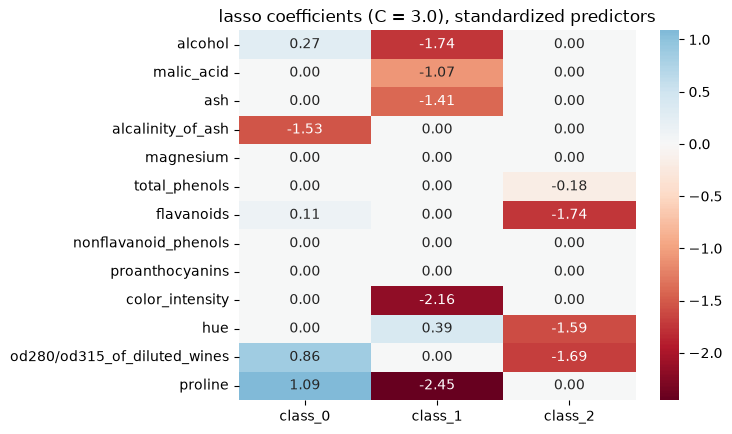

In [13]:
# Now that we have a sense of the C and l1_ratio values that produce the best model
# let's look more specifically at the coefficients it picks out. 

model_best = make_model(C_best, l1_best)
model_best.fit(X_train, y_train)
coef_table = pd.DataFrame(model_best.named_steps["model"].coef_.T,
                          index=X.columns, columns=wine.target_names)

sns.heatmap(coef_table, annot=True, fmt=".2f", cmap="RdBu", center=0)
plt.title(f"{method_best} coefficients (C = {C_best}), standardized predictors")
plt.show()

### Comments on the coefficients

Remember that there is no reference level for multi-nomial classification, all levels are treated equally. So coefficients help us compare two of the three levels. 

Example: Proline. 
* An increase of 1 SD multiplies the odds of class 0 vs class 1 by $\mathrm{e}^{(1.09-(-2.45))}= \mathrm{e}^{3.54} \approx 34$ and class 0 vs class 2 by $\mathrm{e}^{1.09} = \approx 3$

### Confusion matrix (pooled out-of-fold predictions)

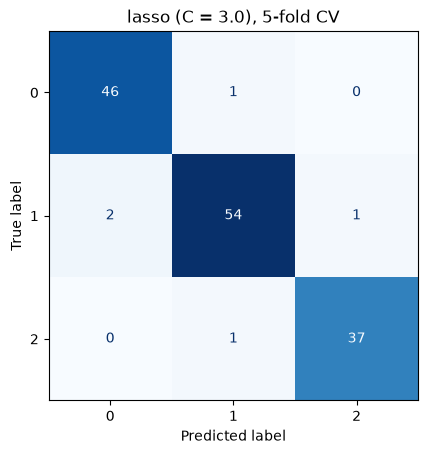

In [14]:
pred_lasso = cv_pred(model_best)
ConfusionMatrixDisplay.from_predictions(y_train, pred_lasso, cmap="Blues", colorbar=False)
plt.title(f"{method_best} (C = {C_best}), 5-fold CV")
plt.show()

## K-Nearest Neighbors

KNN has no coefficients and no penalty. It predicts a wine's class by a vote of its `k` nearest training wines (Euclidean distance on the standardized predictors). The predicted probability for a class is the fraction of the `k` neighbors in that class.

We choose `k` with the same folds we used for our multinomial regression and choose `k` with the lowest mean CV log loss.

In [15]:
def make_knn(k):
    return Pipeline(steps=[
        ("scale", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=k)),
    ])

k_values = range(1, 41, 2)   # odd k avoids some ties

# Note: We are using the same cv_scores function that we used for the multi-nomial logistic regression
knn_results = pd.DataFrame([{"k": k, **cv_scores(make_knn(k))} for k in k_values])
knn_results.round(4)

,k,log loss (mean),log loss (sd)
0,1,2.0330,0.6280
1,3,0.5791,0.5932
2,5,0.3417,0.4850
3,7,0.1042,0.0265
4,9,0.1053,0.0247
5,11,0.1081,0.0197
6,13,0.1153,0.0223
7,15,0.1225,0.0273
8,17,0.1318,0.0284
9,19,0.1345,0.0282


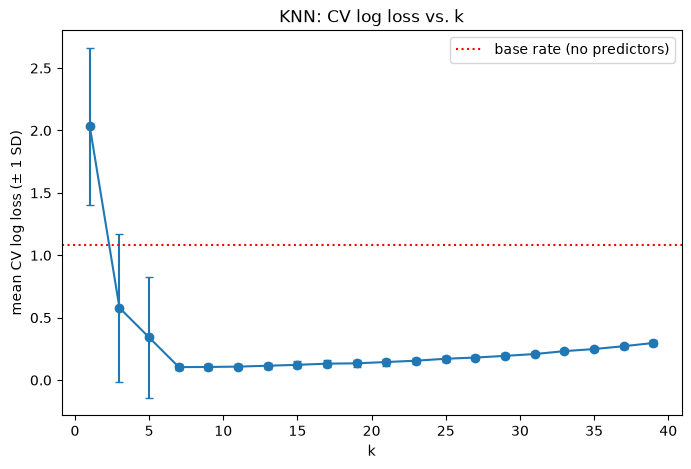

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(knn_results["k"], knn_results["log loss (mean)"], yerr=knn_results["log loss (sd)"],
            marker="o", capsize=3)
ax.axhline(ll_base, color="red", ls=":", label="base rate (no predictors)")
ax.set(xlabel="k", ylabel="mean CV log loss (± 1 SD)", title="KNN: CV log loss vs. k")
ax.legend()
plt.show()

In [17]:
k_best = int(knn_results.loc[knn_results["log loss (mean)"].idxmin(), "k"])
print(f"Best k (lowest mean CV log loss): {k_best}")
model_knn = make_knn(k_best)

Best k (lowest mean CV log loss): 7


Comments:
* **Small `k`:** log loss is huge. With `k = 1` every predicted probability is 0 or 1 (i.e. each model assigns probability 1 to the nearest neighbor's class, and 0 to the other classes.) Each mistake gives the true class a probability of zero, which log loss penalizes heavily.
* **Large `k`:** log loss rises steadily because each prediction averages over more distant neighbors.


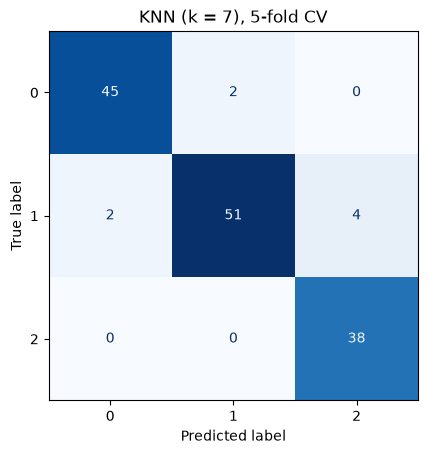

In [18]:
pred_knn = cv_pred(model_knn)
ConfusionMatrixDisplay.from_predictions(y_train, pred_knn, cmap="Blues", colorbar=False)
plt.title(f"KNN (k = {k_best}), 5-fold CV")
plt.show()

## Comparing our best Logistic Regression model and KNN

In [19]:
summary = pd.DataFrame({
    f"{method_best} (C = {C_best})": cv_scores(model_best),
    f"KNN (k = {k_best})": cv_scores(model_knn),
}).T
summary.round(4)

,log loss (mean),log loss (sd)
lasso (C = 3.0),0.0902,0.0669
KNN (k = 7),0.1042,0.0265


In [20]:
# Which training wines does each model get wrong (out-of-fold)?
compare = pd.DataFrame({"actual": y_train, method_best: pred_lasso, "knn": pred_knn})
wrong = compare[(compare[method_best] != compare["actual"]) | (compare["knn"] != compare["actual"])]
print(f"Models agree on {(pred_lasso == pred_knn).mean():.1%} of training wines")
wrong

Models agree on 93.7% of training wines


,actual,lasso,knn
43,0,0,1
130,2,1,2
121,1,0,1
96,1,1,2
38,0,1,0
73,1,0,0
21,0,0,1
68,1,2,2
61,1,1,2
69,1,1,0


How the answers are the same and different:
* The two models agree on around 94% of the training wines. Tee majority of the wines where they differ are class 1.
* Lasso has a lower CV log loss, but only just barely, and the difference is smaller than the fold-to-fold standard deviations. 
* The model mostly make mistakes on different wines. 
* The features and interpretation for these two models are different. Our logistic regression drops several features through the model training process, whereas KNN does not do that so all features weigh equally in the distance calculation. 
* One of the things that KNN helps us determine is the shape of the boundary between the three classes. The Logistic Regression model is linear in the features, though the boundary for KNN can be any shape. The fact that these two models have roughly equivalent performance suggests that a linear boundary between the classes is likely appropriate. 

## Refit on all training data and test once on the holdout set

In [21]:
model_best.fit(X_train, y_train)
model_knn.fit(X_train, y_train)

test_results = pd.DataFrame({
    name: {
        "test log loss": log_loss(y_test, m.predict_proba(X_test)),
    }
    for name, m in [(f"{method_best} (C = {C_best})", model_best), (f"KNN (k = {k_best})", model_knn)]
}).T
test_results.round(4)

,test log loss
lasso (C = 3.0),0.0640
KNN (k = 7),0.0984


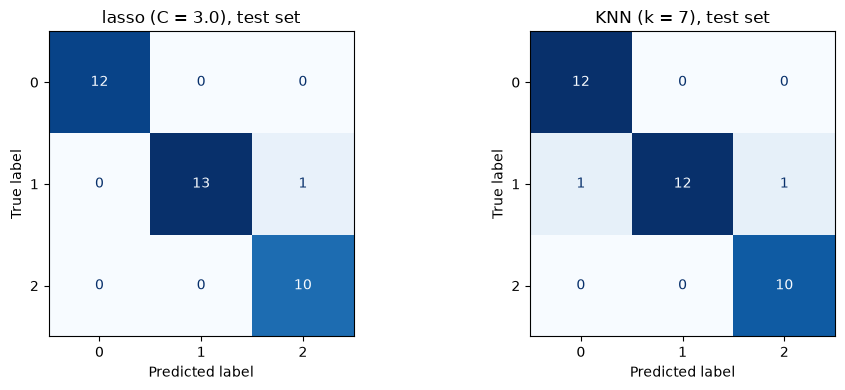

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, m) in zip(axes, [(f"{method_best} (C = {C_best})", model_best), (f"KNN (k = {k_best})", model_knn)]):
    ConfusionMatrixDisplay.from_predictions(y_test, m.predict(X_test), ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}, test set")
plt.tight_layout()
plt.show()

Comments on the holdout results:
* Both models beat the base rate (log loss 1.085) by a wide margin on new data.
* Logstic regression still has the lower log loss. 